In [5]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from matplotlib import pyplot as plt
from sklearn.cluster import KMeans
%matplotlib inline

In [3]:
df = pd.read_csv("income.csv")
df.head()

,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000


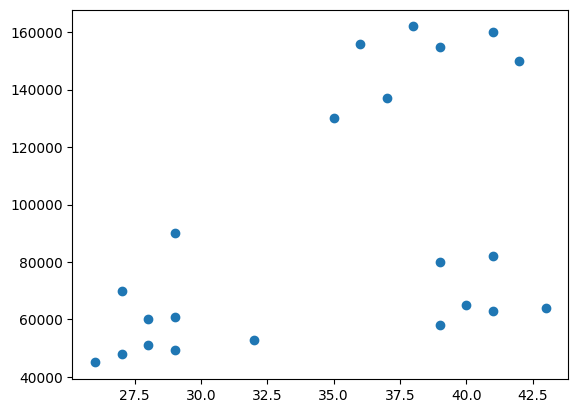

In [4]:
plt.scatter(df['Age'],df['Income($)'])

In [6]:
# we can see k = 3 
k = 3
kmeans = KMeans(n_clusters=k)

In [11]:
y_p = kmeans.fit_predict(df[["Age", "Income($)"]])

In [12]:
df['cluster'] = y_p

In [13]:
df.head()

,Name,Age,Income($),cluster
0,Rob,27,70000,0
1,Michael,29,90000,2
2,Mohan,29,61000,0
3,Ismail,28,60000,0
4,Kory,42,150000,1


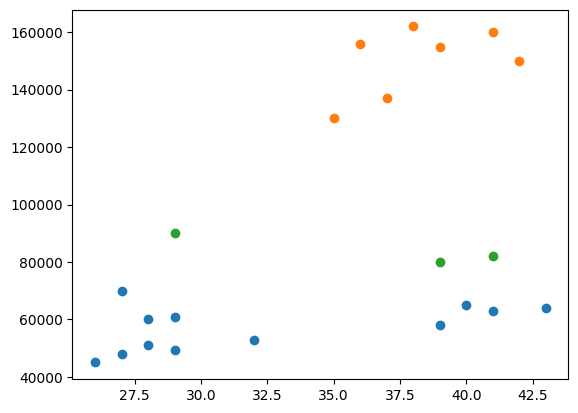

In [19]:
df1 = df[df.cluster == 0]
df2 = df[df.cluster == 1]
df3 = df[df.cluster == 2]

plt.scatter(df1['Age'], df1['Income($)'])
plt.scatter(df2['Age'], df2['Income($)'])
plt.scatter(df3['Age'], df3['Income($)'])

In [20]:
scaler = MinMaxScaler()

In [24]:
new_df = scaler.fit_transform(df[['Age','Income($)']])

In [28]:
kmeans2 = KMeans(n_clusters=3)

In [31]:
y_p2 = kmeans2.fit_predict(new_df)

In [35]:
new_dff = pd.DataFrame(new_df, columns=["Age","Income($)"])
new_dff['cluster'] = y_p2

In [36]:
new_dff.head()

,Age,Income($),cluster
0,0.058824,0.213675,1
1,0.176471,0.384615,1
2,0.176471,0.136752,1
3,0.117647,0.128205,1
4,0.941176,0.897436,2


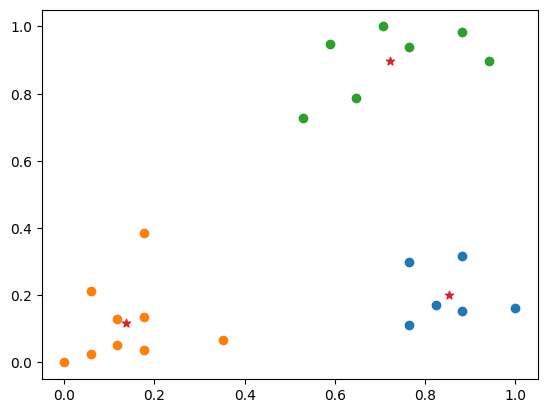

In [41]:
df = new_dff
df1 = df[df.cluster == 0]
df2 = df[df.cluster == 1]
df3 = df[df.cluster == 2]

plt.scatter(df1['Age'], df1['Income($)'])
plt.scatter(df2['Age'], df2['Income($)'])
plt.scatter(df3['Age'], df3['Income($)'])

# Centroid
plt.scatter(kmeans2.cluster_centers_[:,0], kmeans2.cluster_centers_[:,1], marker="*", label="Centroid")

In [38]:
kmeans2.cluster_centers_

array([[0.85294118, 0.2022792 ],
       [0.1372549 , 0.11633428],
       [0.72268908, 0.8974359 ]])

## Elbow Technique      

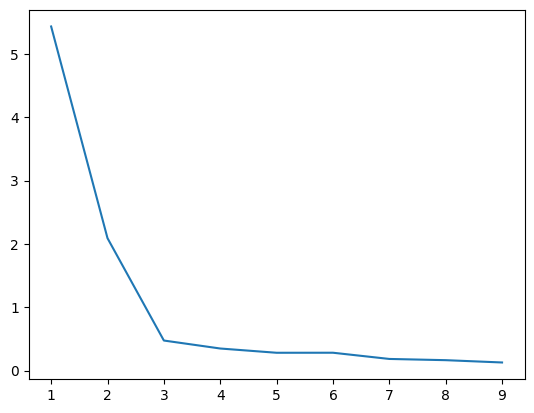

In [20]:
sse = []

k_range = range(1,10)

for k in k_range:
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(df[["Age", "Income($)"]])
    sse.append(kmeans.inertia_)

plt.plot(k_range, sse)